# Notebook 11 - Validación del modelo contra Copernicus EMS

Cruza la huella real de inundación (EMSR773 - DANA octubre 2024) con las predicciones del modelo para obtener métricas de validación frente a verdad terreno.

In [ ]:
import sys
from pathlib import Path

# Permitir importar desde src/
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from src.config import RAW_DIR, PROCESSED_DIR

# Ruta a los datos de Copernicus
COPERNICUS_DIR = RAW_DIR / "copernicus" / "EMSR773_AOI01_DEL_MONIT04_v1"

# Capa que vamos a usar: la extensión máxima de la inundación
SHAPEFILE_INUNDACION = COPERNICUS_DIR / "EMSR773_AOI01_DEL_MONIT04_maximumFloodExtentA_v1.shp"

print(f"Ruta de Copernicus: {COPERNICUS_DIR}")
print(f"¿Existe el shapefile? {SHAPEFILE_INUNDACION.exists()}")

Ruta de Copernicus: C:\Users\Maria\Documents\tfm-flood-warning\data\raw\copernicus\EMSR773_AOI01_DEL_MONIT04_v1
¿Existe el shapefile? True


In [3]:
# Cargar el shapefile de la huella de inundación máxima
huella = gpd.read_file(SHAPEFILE_INUNDACION)

print(f"Número de polígonos: {len(huella)}")
print(f"Sistema de referencia espacial (CRS): {huella.crs}")
print(f"\nPrimeras filas:")
huella.head()

Número de polígonos: 912
Sistema de referencia espacial (CRS): EPSG:4326

Primeras filas:


,event_type,obj_desc,det_method,notation,dmg_src_id,area,geometry
0,5-Flood,Flash flood,Semi-automatic extraction,Maximum flood extent,997,1.548752,"POLYGON ((-0.05774 38.85463, -0.05774 38.85454..."
1,5-Flood,Flash flood,Semi-automatic extraction,Maximum flood extent,997,1.688593,"POLYGON ((-0.03181 38.85488, -0.03181 38.85479..."
2,5-Flood,Flash flood,Semi-automatic extraction,Maximum flood extent,997,0.589513,"POLYGON ((-0.03969 38.85652, -0.03969 38.85643..."
3,5-Flood,Flash flood,Semi-automatic extraction,Maximum flood extent,997,0.679429,"POLYGON ((-0.02562 38.8567, -0.02563 38.85661,..."
4,5-Flood,Flash flood,Semi-automatic extraction,Maximum flood extent,997,12.899654,"POLYGON ((-0.06154 38.85761, -0.06154 38.85752..."


In [4]:
# Cada polígono lleva atributos asociados (tabla)
print("Columnas disponibles:")
print(huella.columns.tolist())
print(f"\nTipos de datos:")
print(huella.dtypes)

Columnas disponibles:
['event_type', 'obj_desc', 'det_method', 'notation', 'dmg_src_id', 'area', 'geometry']

Tipos de datos:
event_type         str
obj_desc           str
det_method         str
notation           str
dmg_src_id       int32
area           float64
geometry      geometry
dtype: object


In [5]:
# Reproyectar a WGS84 (lat/lon), que es el sistema en el que están las estaciones
huella_wgs84 = huella.to_crs(epsg=4326)

print(f"CRS original: {huella.crs}")
print(f"CRS nuevo:    {huella_wgs84.crs}")

CRS original: EPSG:4326
CRS nuevo:    EPSG:4326


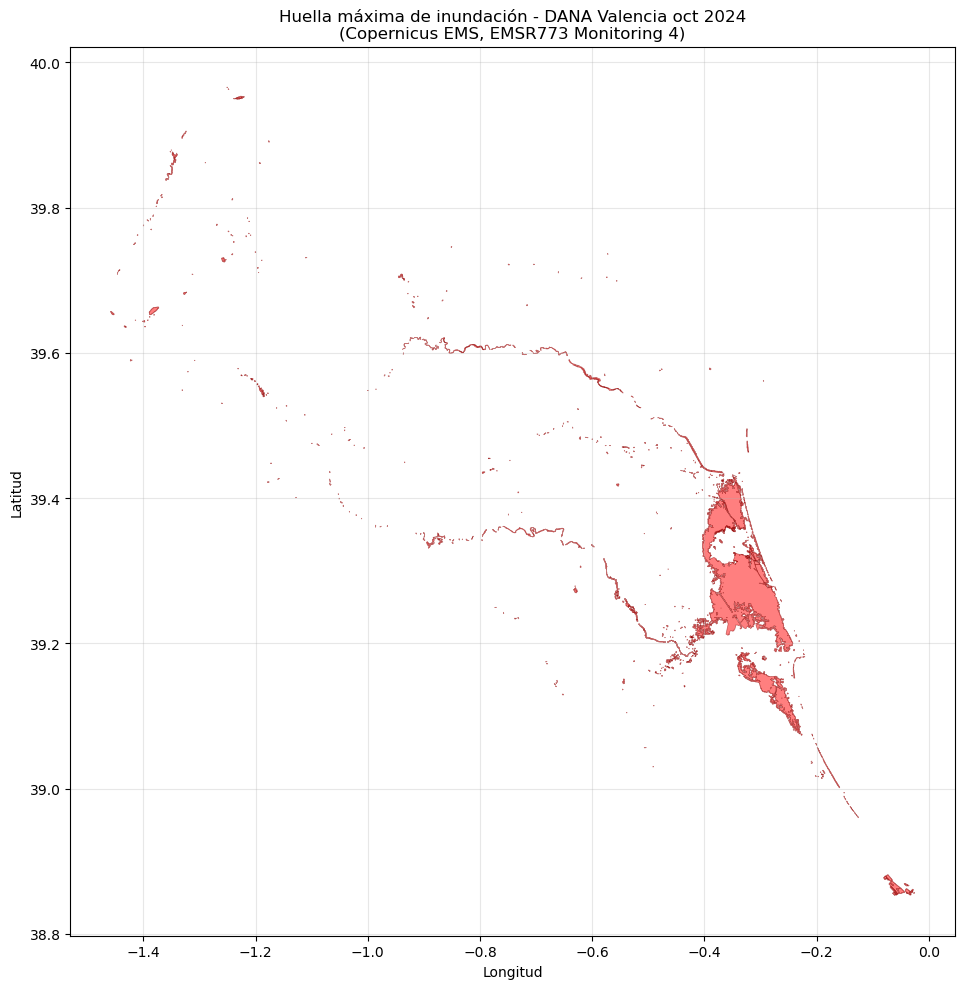

In [6]:
# Visualización básica para confirmar que es la zona correcta
fig, ax = plt.subplots(figsize=(12, 10))
huella_wgs84.plot(ax=ax, color='red', alpha=0.5, edgecolor='darkred', linewidth=0.5)
ax.set_title('Huella máxima de inundación - DANA Valencia oct 2024\n(Copernicus EMS, EMSR773 Monitoring 4)')
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# Cargar las estaciones del SAIH geolocalizadas
saih_path = PROCESSED_DIR / "saih_geolocalizado_2020_2024.parquet"
saih_full = pd.read_parquet(saih_path)

print(f"Total de registros del SAIH: {len(saih_full)}")
print(f"Columnas: {saih_full.columns.tolist()}")

Total de registros del SAIH: 31697
Columnas: ['fecha', 'subcuenca', 'descripcion', 'provincia', 'precipitacion_mm', 'match_final', 'lat', 'lon', 'fuente_coords']


Para la validación no necesitamos todas las observaciones diarias, solo la lista única de estaciones con sus coordenadas. Una estación está en un sitio fijo: sus coordenadas son las mismas todos los días.


In [18]:
# Quedarnos con una fila por estación (la lista única) - incluyendo 'descripcion'
estaciones = (
    saih_full
    .dropna(subset=['lat', 'lon'])
    .drop_duplicates(subset=['descripcion'])   # ahora por descripcion
    [['descripcion', 'match_final', 'subcuenca', 'provincia', 
      'lat', 'lon', 'fuente_coords']]
    .reset_index(drop=True)
)

print(f"Número de estaciones únicas geolocalizadas: {len(estaciones)}")
estaciones.head(10)

Número de estaciones únicas geolocalizadas: 115


,descripcion,match_final,subcuenca,provincia,lat,lon,fuente_coords
0,Embalse de Ulldecona La Pobla de Benifassa,ULLDECONA,CENIA-BAJO MAESTRAZGO,CS,40.671433,0.233323,shapefile_miteco
1,Pluvionivómetro de Fredes La Pobla de Benifassa,FREDES,CENIA-BAJO MAESTRAZGO,CS,40.695043,0.167687,shapefile_miteco
2,Pluvionivómetro de Vallibona Morella,VALLIBONA,CENIA-BAJO MAESTRAZGO,CS,40.584792,0.001111,shapefile_miteco
3,Pluviómetro de Catí Catí,CATI,CENIA-BAJO MAESTRAZGO,CS,40.494052,0.008751,shapefile_miteco
4,Pluviómetro de Xert Xert,XERT,CENIA-BAJO MAESTRAZGO,CS,40.517032,0.160356,shapefile_miteco
5,Aforo en Cuenca Cuenca,CUENCA,DEL ALTO JUCAR,CU,40.075462,-2.140587,shapefile_miteco
6,Aforo en Pajaroncillo Pajaroncillo,PAJARONCILLO,DEL ALTO JUCAR,CU,39.940924,-1.711426,shapefile_miteco
7,Embalse de Alarcón Alarcón,ALARCON,DEL ALTO JUCAR,CU,39.565100,-2.111824,shapefile_miteco
8,Embalse de la Toba Uña,LA TOBA,DEL ALTO JUCAR,CU,40.211093,-1.922047,shapefile_miteco
9,Pluvionivometro Tío Calores Barchin del Hoyo,TIO CALORES,DEL ALTO JUCAR,CU,39.671824,-1.944377,shapefile_miteco


Convertir las estaciones a GeoDataFrame para que geopandas pueda cruzarlas con la huella, las estaciones también tienen que ser un GeoDataFrame (no un DataFrame normal).

In [19]:
# Convertir el DataFrame de estaciones en GeoDataFrame con geometría de puntos
estaciones_gdf = gpd.GeoDataFrame(
    estaciones,
    geometry=gpd.points_from_xy(estaciones['lon'], estaciones['lat']),
    crs="EPSG:4326"  # Mismo sistema que la huella de Copernicus
)

print(f"Tipo: {type(estaciones_gdf)}")
print(f"CRS: {estaciones_gdf.crs}")
estaciones_gdf.head()

Tipo: <class 'geopandas.geodataframe.GeoDataFrame'>
CRS: EPSG:4326


,descripcion,match_final,subcuenca,provincia,lat,lon,fuente_coords,geometry
0,Embalse de Ulldecona La Pobla de Benifassa,ULLDECONA,CENIA-BAJO MAESTRAZGO,CS,40.671433,0.233323,shapefile_miteco,POINT (0.23332 40.67143)
1,Pluvionivómetro de Fredes La Pobla de Benifassa,FREDES,CENIA-BAJO MAESTRAZGO,CS,40.695043,0.167687,shapefile_miteco,POINT (0.16769 40.69504)
2,Pluvionivómetro de Vallibona Morella,VALLIBONA,CENIA-BAJO MAESTRAZGO,CS,40.584792,0.001111,shapefile_miteco,POINT (0.00111 40.58479)
3,Pluviómetro de Catí Catí,CATI,CENIA-BAJO MAESTRAZGO,CS,40.494052,0.008751,shapefile_miteco,POINT (0.00875 40.49405)
4,Pluviómetro de Xert Xert,XERT,CENIA-BAJO MAESTRAZGO,CS,40.517032,0.160356,shapefile_miteco,POINT (0.16036 40.51703)


C:\Users\Maria\AppData\Local\Temp\ipykernel_60112\3130056777.py:31: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(loc='upper left')


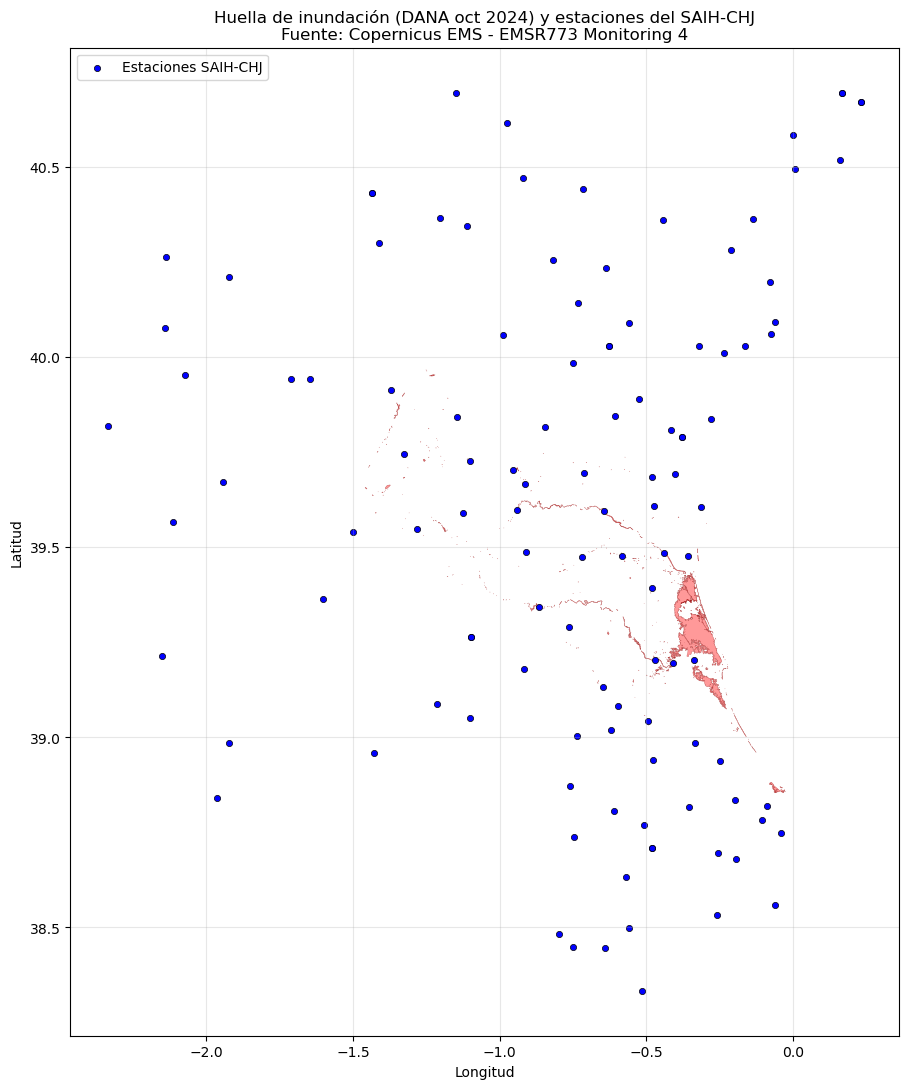

In [20]:
# Visualizar la huella de Copernicus + estaciones del SAIH superpuestas
fig, ax = plt.subplots(figsize=(14, 11))

# Huella de inundación en rojo
huella_wgs84.plot(
    ax=ax, 
    color='red', 
    alpha=0.4, 
    edgecolor='darkred', 
    linewidth=0.3,
    label='Zona inundada (Copernicus EMS)'
)

# Estaciones del SAIH como puntos azules
estaciones_gdf.plot(
    ax=ax, 
    color='blue', 
    markersize=20, 
    edgecolor='black', 
    linewidth=0.5,
    label='Estaciones SAIH-CHJ'
)

ax.set_title(
    'Huella de inundación (DANA oct 2024) y estaciones del SAIH-CHJ\n'
    'Fuente: Copernicus EMS - EMSR773 Monitoring 4',
    fontsize=12
)
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.legend(loc='upper left')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

"Cerca de la zona inundada" no es lo mismo que "dentro". Y aquí hay un matiz importante para tu validación.Una estación del SAIH es un pluviómetro o aforo, que se sitúa donde se mide la lluvia o el caudal — no necesariamente donde se inunda. De hecho, las estaciones críticas (Chiva, Forata) están en cabecera, donde llovió pero no se inundó. Lo que se inundó está aguas abajo (Paiporta, Catarroja, donde casi no hay estaciones).Esto significa que una estación "fuera" de la huella no significa que el modelo se haya equivocado al alertarla. Significa que la estación está en cabecera y la inundación está aguas abajo — que es justamente la dinámica del evento.Por eso vamos a etiquetar las estaciones con un buffer (zona de influencia): si una estación está dentro o cerca (a menos de X km) de la huella, consideramos que "su zona de influencia se inundó". Esto es metodológicamente más correcto.Te lo cuento porque luego en la memoria tienes que justificarlo, y así sabes el porqué desde ya.

In [21]:
# Para etiquetar cada estación según si su zona se inundó, usamos un buffer 
# alrededor del punto de la estación. La idea es: una estación "ve" un área
# circundante de unos pocos km. Si esa área se inundó, etiquetamos la estación
# como zona inundada.
#
# Trabajamos en metros para que el buffer sea entendible. Para ello reproyectamos
# temporalmente a UTM 30N (EPSG:25830), un sistema métrico estándar en España.

BUFFER_METROS = 5000  # 5 km de radio alrededor de cada estación

# Reproyectar todo a UTM para trabajar en metros
estaciones_utm = estaciones_gdf.to_crs(epsg=25830)
huella_utm = huella_wgs84.to_crs(epsg=25830)

# Aplicar buffer alrededor de cada estación
estaciones_utm['buffer'] = estaciones_utm.geometry.buffer(BUFFER_METROS)

# Unir todos los polígonos de la huella en uno solo (para simplificar el cruce)
huella_unificada = huella_utm.geometry.unary_union

# Etiquetar cada estación: ¿su buffer intersecta con la huella?
estaciones_utm['zona_inundada'] = estaciones_utm['buffer'].intersects(huella_unificada)

# Contar
n_dentro = estaciones_utm['zona_inundada'].sum()
n_fuera = (~estaciones_utm['zona_inundada']).sum()

print(f"Estaciones cuya zona de influencia (5 km) se inundó: {n_dentro}")
print(f"Estaciones fuera de zona inundada:                   {n_fuera}")
print(f"Total:                                                {len(estaciones_utm)}")

C:\Users\Maria\AppData\Local\Temp\ipykernel_60112\233003800.py:19: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  huella_unificada = huella_utm.geometry.unary_union


Estaciones cuya zona de influencia (5 km) se inundó: 25
Estaciones fuera de zona inundada:                   90
Total:                                                115


In [22]:
# Inspeccionar qué estaciones quedaron etiquetadas como zona inundada
estaciones_inundadas = estaciones_utm[estaciones_utm['zona_inundada']].copy()

# Ordenar para verlas
print("Estaciones con zona de influencia inundada:")
print(estaciones_inundadas[['match_final', 'subcuenca', 'provincia']].to_string(index=False))

Estaciones con zona de influencia inundada:
 match_final                                  subcuenca provincia
     LANDETE                             DEL ALTO JUCAR        CU
      DOMENO                             DEL ALTO TURIA         V
   BENAGEBER                             DEL ALTO TURIA         V
  LORIGUILLA                             DEL ALTO TURIA         V
HUERTO MULET                             DEL BAJO JUCAR         V
  GUADASSUAR                             DEL BAJO JUCAR         V
       SUECA                             DEL BAJO JUCAR         V
   PICASSENT                             DEL BAJO JUCAR         V
      MANUEL                             DEL BAJO JUCAR         V
 SIETE AGUAS                             DEL BAJO JUCAR         V
 REPARTIMENT                             DEL BAJO TURIA         V
       BUSEO                             DEL BAJO TURIA         V
   CARRAIXET                             DEL BAJO TURIA         V
 RAMBLA POYO                    

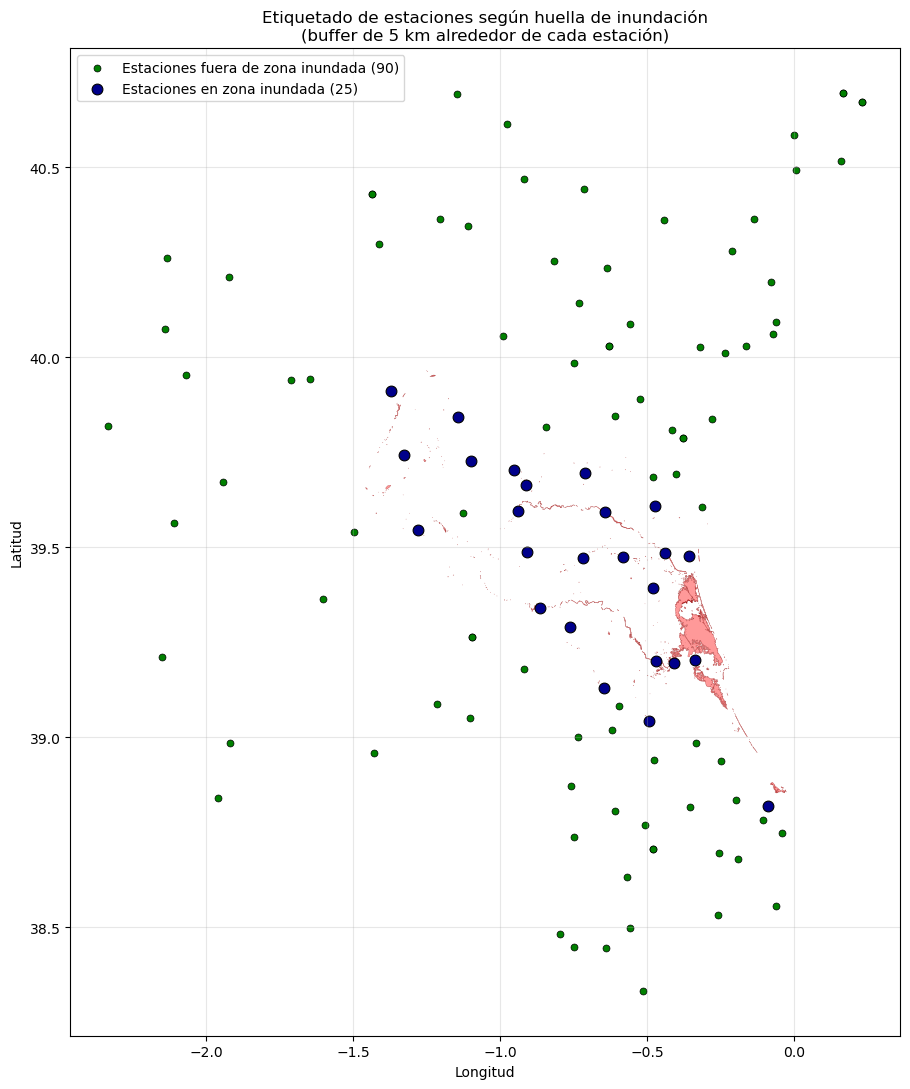

In [23]:
# Visualización del resultado: estaciones coloreadas según etiqueta
fig, ax = plt.subplots(figsize=(14, 11))

# Huella en rojo translúcido
huella_wgs84.plot(ax=ax, color='red', alpha=0.4, edgecolor='darkred', linewidth=0.3)

# Estaciones fuera de zona inundada (verde)
estaciones_fuera = estaciones_gdf[~estaciones_utm['zona_inundada'].values]
estaciones_fuera.plot(
    ax=ax, color='green', markersize=25, edgecolor='black', linewidth=0.5,
    label=f'Estaciones fuera de zona inundada ({len(estaciones_fuera)})'
)

# Estaciones dentro de zona inundada (azul oscuro)
estaciones_dentro = estaciones_gdf[estaciones_utm['zona_inundada'].values]
estaciones_dentro.plot(
    ax=ax, color='darkblue', markersize=60, edgecolor='black', linewidth=0.8,
    label=f'Estaciones en zona inundada ({len(estaciones_dentro)})'
)

ax.set_title(
    f'Etiquetado de estaciones según huella de inundación\n'
    f'(buffer de {BUFFER_METROS/1000:.0f} km alrededor de cada estación)',
    fontsize=12
)
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.legend(loc='upper left')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Antes de seguir, una decisión que conviene que entiendas: tu modelo es de predicción anticipada (features del día X → riesgo del día X+1). Por tanto, para predecir el riesgo del 29 de octubre (día de la inundación), las features deben ser las del 28 de octubre. Eso es lo que vamos a hacer — es lo metodológicamente correcto.

Cargar el modelo y las features

In [24]:
import pickle

# Cargar el modelo entrenado (el de la Mejora 3, hiperparámetros optimizados)
MODELO_PATH = Path.cwd().parent / "models" / "modelo_riesgo_inundacion.pkl"
with open(MODELO_PATH, "rb") as f:
    modelo = pickle.load(f)

print(f"Modelo cargado: {type(modelo).__name__}")

# Cargar las features
features_path = PROCESSED_DIR / "features_modelo_RECONSTRUCCION.parquet"
features = pd.read_parquet(features_path)

print(f"Total de filas de features: {len(features)}")
print(f"Rango de fechas: {features['fecha'].min()} a {features['fecha'].max()}")

Modelo cargado: XGBClassifier
Total de filas de features: 19747
Rango de fechas: 2020-01-19 00:00:00 a 2024-11-13 00:00:00


In [25]:
# Filtrar las features del 28 de octubre (para predecir el riesgo del 29)
features_28oct = features[features['fecha'] == pd.Timestamp('2024-10-28')].copy()

print(f"Estaciones con registro el 28 de octubre: {len(features_28oct)}")

# Lista de features del modelo (orden exacto del entrenamiento)
FEATURES_MODELO = [
    'precip_dia', 'precip_3d', 'precip_7d', 'precip_previa_7d',
    'elevacion', 'pendiente',
    'mes', 'temporada_lluvias',
    'precip_tendencia', 'ratio_reciente', 'precip_max_3d', 'dias_consecutivos_lluvia'
]

# Aplicar el modelo
X = features_28oct[FEATURES_MODELO]
features_28oct['probabilidad_riesgo'] = modelo.predict_proba(X)[:, 1]

# Aplicar umbral de alerta (mismo del sistema en streaming)
UMBRAL = 0.30
features_28oct['alerta_modelo'] = features_28oct['probabilidad_riesgo'] >= UMBRAL

n_alertas = features_28oct['alerta_modelo'].sum()
print(f"\nAlertas emitidas para el 29-oct: {n_alertas} de {len(features_28oct)} estaciones")

Estaciones con registro el 28 de octubre: 109

Alertas emitidas para el 29-oct: 7 de 109 estaciones


In [26]:
print("Columnas de features_28oct:")
print(features_28oct.columns.tolist())
print()
print("Primeras filas para identificar la columna de estación:")
features_28oct.head(3)

Columnas de features_28oct:
['descripcion', 'fecha', 'lat', 'lon', 'subcuenca', 'precip_dia', 'precip_3d', 'precip_7d', 'precip_previa_7d', 'elevacion', 'pendiente', 'mes', 'temporada_lluvias', 'precip_tendencia', 'ratio_reciente', 'precip_max_3d', 'dias_consecutivos_lluvia', 'probabilidad_riesgo', 'alerta_modelo']

Primeras filas para identificar la columna de estación:


,descripcion,fecha,lat,lon,subcuenca,precip_dia,precip_3d,precip_7d,precip_previa_7d,elevacion,pendiente,mes,temporada_lluvias,precip_tendencia,ratio_reciente,precip_max_3d,dias_consecutivos_lluvia,probabilidad_riesgo,alerta_modelo
167,Acequia Moncada El Puig,2024-10-28,39.605677,-0.314405,DEL BAJO TURIA,8.4,8.4,49.8,41.4,18.675497,0.600955,10,1,-19.6,0.168675,8.4,4,0.032925,False
342,Aforo Trasvase Tajo-Segura Los Anguijes,2024-10-28,38.839421,-1.962372,DEL JUCAR MEDIO,3.2,3.2,40.2,37.0,713.216858,0.705203,10,1,-33.8,0.079602,3.2,2,0.005955,False
520,Aforo en Cofrentes Cofrentes,2024-10-28,39.263031,-1.096256,DEL JUCAR MEDIO,31.2,31.2,49.8,18.6,346.887604,5.799316,10,1,13.6,0.626506,31.2,2,0.197287,False


In [27]:
# Preparar tablas para el cruce
predicciones = features_28oct[['descripcion', 'probabilidad_riesgo', 'alerta_modelo']]

etiquetas = pd.DataFrame({
    'descripcion': estaciones_utm['descripcion'].values,
    'zona_inundada': estaciones_utm['zona_inundada'].values
})

# Unir por descripcion (solo las que tienen ambas: predicción y verdad terreno)
validacion = predicciones.merge(etiquetas, on='descripcion', how='inner')

print(f"Estaciones evaluadas (con predicción y verdad terreno): {len(validacion)}")
print(f"  De las cuales en zona inundada: {validacion['zona_inundada'].sum()}")
print(f"  Y con alerta del modelo:        {validacion['alerta_modelo'].sum()}")

Estaciones evaluadas (con predicción y verdad terreno): 109
  De las cuales en zona inundada: 24
  Y con alerta del modelo:        7


In [28]:
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score
)

y_true = validacion['zona_inundada'].astype(int)
y_pred = validacion['alerta_modelo'].astype(int)
y_proba = validacion['probabilidad_riesgo']

# Matriz de confusión
cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

print("=" * 60)
print("MATRIZ DE CONFUSIÓN - Validación frente a Copernicus EMS")
print("=" * 60)
print(f"                             Pred: NO alerta   Pred: ALERTA")
print(f"  Real: NO inundada (terreno)    {tn:>8}        {fp:>8}")
print(f"  Real: inundada (Copernicus)    {fn:>8}        {tp:>8}")
print()
print(f"  Verdaderos positivos (acierto):       {tp}")
print(f"  Falsos positivos (alerta innecesaria): {fp}")
print(f"  Falsos negativos (alerta no emitida):  {fn}")
print(f"  Verdaderos negativos (correcto):       {tn}")
print()
print("=" * 60)
print("MÉTRICAS")
print("=" * 60)
print(f"  Precision:  {precision_score(y_true, y_pred):.3f}")
print(f"  Recall:     {recall_score(y_true, y_pred):.3f}")
print(f"  F1-score:   {f1_score(y_true, y_pred):.3f}")
print(f"  AUC-ROC:    {roc_auc_score(y_true, y_proba):.3f}")
print(f"  Accuracy:   {(tp+tn)/(tp+tn+fp+fn):.3f}")

MATRIZ DE CONFUSIÓN - Validación frente a Copernicus EMS
                             Pred: NO alerta   Pred: ALERTA
  Real: NO inundada (terreno)          82               3
  Real: inundada (Copernicus)          20               4

  Verdaderos positivos (acierto):       4
  Falsos positivos (alerta innecesaria): 3
  Falsos negativos (alerta no emitida):  20
  Verdaderos negativos (correcto):       82

MÉTRICAS
  Precision:  0.571
  Recall:     0.167
  F1-score:   0.258
  AUC-ROC:    0.586
  Accuracy:   0.789


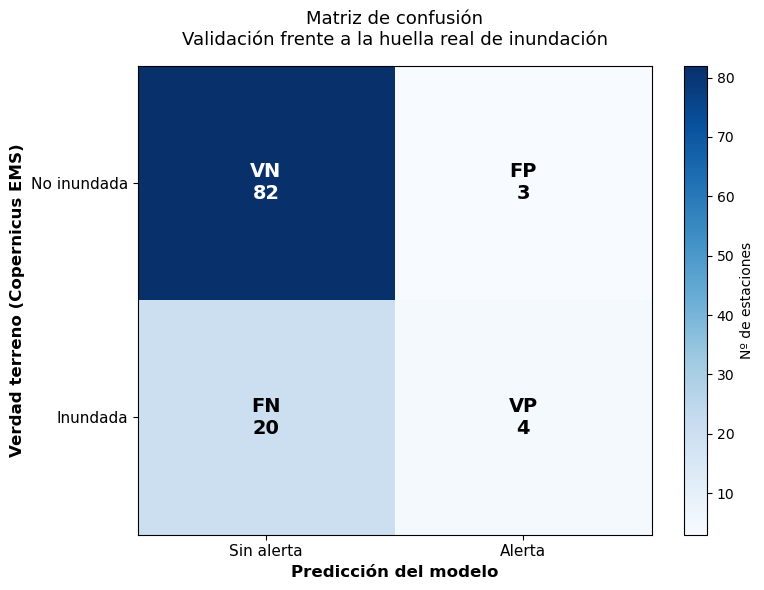

In [29]:
import numpy as np

fig, ax = plt.subplots(figsize=(8, 6))

# Pintar matriz como heatmap
im = ax.imshow(cm, cmap='Blues', aspect='auto')

# Etiquetas
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Sin alerta', 'Alerta'], fontsize=11)
ax.set_yticklabels(['No inundada', 'Inundada'], fontsize=11)
ax.set_xlabel('Predicción del modelo', fontsize=12, fontweight='bold')
ax.set_ylabel('Verdad terreno (Copernicus EMS)', fontsize=12, fontweight='bold')
ax.set_title('Matriz de confusión\nValidación frente a la huella real de inundación', 
             fontsize=13, pad=15)

# Anotar los valores en cada celda
labels_celdas = [
    [f'VN\n{tn}', f'FP\n{fp}'],
    [f'FN\n{fn}', f'VP\n{tp}']
]
for i in range(2):
    for j in range(2):
        color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
        ax.text(j, i, labels_celdas[i][j], ha='center', va='center', 
                fontsize=14, color=color, fontweight='bold')

plt.colorbar(im, ax=ax, label='Nº de estaciones')
plt.tight_layout()
plt.savefig(Path.cwd().parent / 'data' / 'processed' / 'matriz_confusion_copernicus.png', 
            dpi=150, bbox_inches='tight')
plt.show()

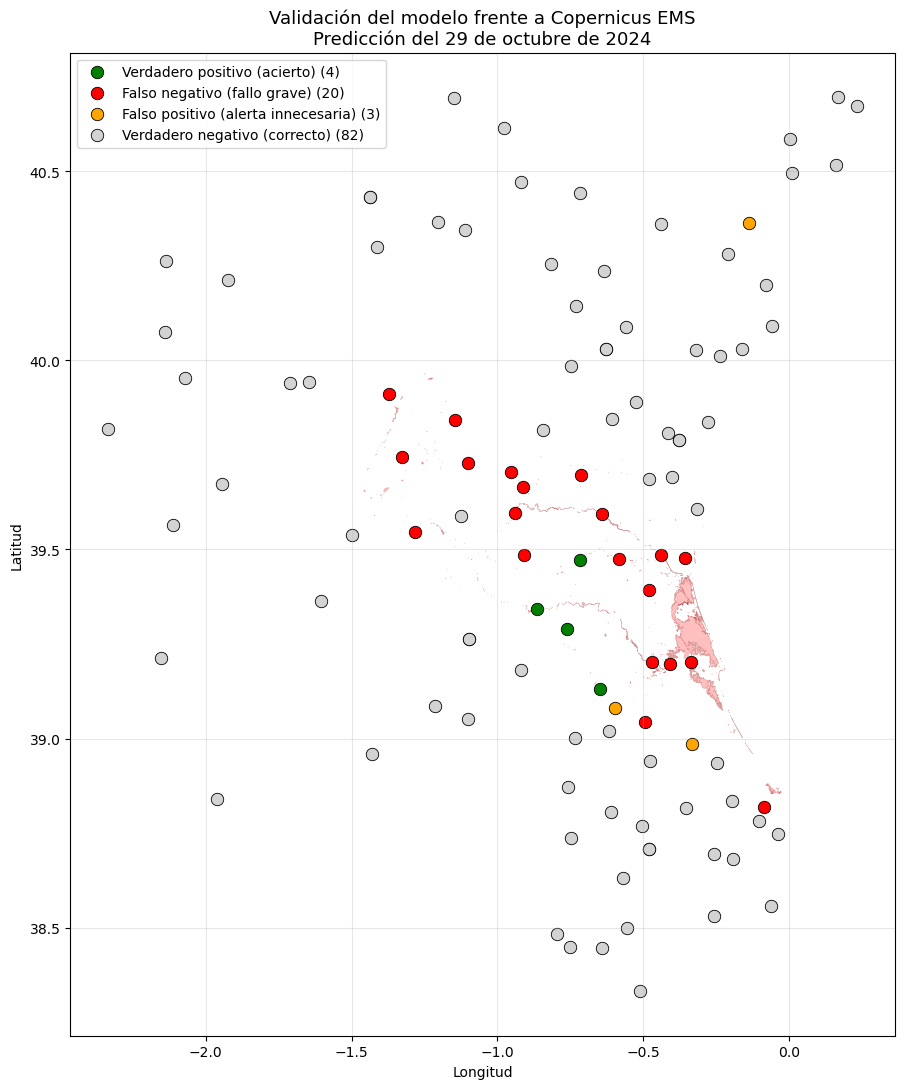

In [30]:
# Cruzar también con el GeoDataFrame para poder pintar el mapa
mapa_validacion = estaciones_gdf.merge(validacion, on='descripcion', how='inner').copy()

# (el resto de la celda queda igual)
def clasificar(row):
    if row['zona_inundada'] and row['alerta_modelo']:
        return 'Verdadero positivo (acierto)'
    elif row['zona_inundada'] and not row['alerta_modelo']:
        return 'Falso negativo (fallo grave)'
    elif not row['zona_inundada'] and row['alerta_modelo']:
        return 'Falso positivo (alerta innecesaria)'
    else:
        return 'Verdadero negativo (correcto)'

mapa_validacion['resultado'] = mapa_validacion.apply(clasificar, axis=1)

colores = {
    'Verdadero positivo (acierto)':       'green',
    'Falso negativo (fallo grave)':       'red',
    'Falso positivo (alerta innecesaria)':'orange',
    'Verdadero negativo (correcto)':      'lightgray'
}

fig, ax = plt.subplots(figsize=(14, 11))
huella_wgs84.plot(ax=ax, color='red', alpha=0.25, edgecolor='darkred', linewidth=0.3)

for categoria, color in colores.items():
    subset = mapa_validacion[mapa_validacion['resultado'] == categoria]
    if len(subset) > 0:
        subset.plot(
            ax=ax, color=color, markersize=80, edgecolor='black', linewidth=0.6,
            label=f'{categoria} ({len(subset)})'
        )

ax.set_title('Validación del modelo frente a Copernicus EMS\nPredicción del 29 de octubre de 2024',
             fontsize=13)
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.legend(loc='upper left', fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(Path.cwd().parent / 'data' / 'processed' / 'mapa_validacion_copernicus.png',
            dpi=150, bbox_inches='tight')
plt.show()

In [31]:
validacion_completa = mapa_validacion[
    ['descripcion', 'subcuenca', 'provincia', 'lat', 'lon',
     'probabilidad_riesgo', 'alerta_modelo', 'zona_inundada', 'resultado']
].copy()

output_path = PROCESSED_DIR / "validacion_copernicus.csv"
validacion_completa.to_csv(output_path, index=False, encoding='utf-8')

print(f"Guardado en: {output_path}")
print(f"\nResumen por categoría:")
print(validacion_completa['resultado'].value_counts())

Guardado en: C:\Users\Maria\Documents\tfm-flood-warning\data\processed\validacion_copernicus.csv

Resumen por categoría:
resultado
Verdadero negativo (correcto)          82
Falso negativo (fallo grave)           20
Verdadero positivo (acierto)            4
Falso positivo (alerta innecesaria)     3
Name: count, dtype: int64


In [32]:
# 1) Ver QUÉ estaciones son falsos negativos (las rojas en el mapa)
falsos_negativos = mapa_validacion[
    (mapa_validacion['zona_inundada']) & (~mapa_validacion['alerta_modelo'])
][['descripcion', 'subcuenca', 'lat', 'lon', 'probabilidad_riesgo']]
falsos_negativos = falsos_negativos.sort_values('probabilidad_riesgo', ascending=False)

print("ESTACIONES MARCADAS COMO 'EN ZONA INUNDADA' QUE EL MODELO NO ALERTÓ:")
print(falsos_negativos.to_string(index=False))

ESTACIONES MARCADAS COMO 'EN ZONA INUNDADA' QUE EL MODELO NO ALERTÓ:
                                                 descripcion                                  subcuenca       lat       lon  probabilidad_riesgo
               Aforo en acequia Real (Guadassuar) Guadassuar                             DEL BAJO JUCAR 39.201355 -0.470955             0.230366
                                      Embalse de Buseo Chera                             DEL BAJO TURIA 39.596577 -0.939375             0.173207
                                 Marco en rio Albaida Manuel                             DEL BAJO JUCAR 39.042359 -0.494510             0.152874
                      Pluviómetro de Siete Aguas Siete Aguas                             DEL BAJO JUCAR 39.486369 -0.908995             0.106958
                                         Azud de Sueca Riola                             DEL BAJO JUCAR 39.202360 -0.335866             0.062343
                    Canal Júcar-Turia en Picassent Picassent 

In [33]:
# 2) Ver qué precipitación tenían esas estaciones el 28-oct (las features que vio el modelo)
falsos_negativos_features = features_28oct.merge(
    falsos_negativos[['descripcion']], on='descripcion'
)[['descripcion', 'precip_dia', 'precip_3d', 'precip_max_3d', 'probabilidad_riesgo']]

print("\nFEATURES DEL 28-OCT DE LOS FALSOS NEGATIVOS:")
print(falsos_negativos_features.to_string(index=False))


FEATURES DEL 28-OCT DE LOS FALSOS NEGATIVOS:
                                                 descripcion  precip_dia  precip_3d  precip_max_3d  probabilidad_riesgo
                              Aforo en Huerto Mulet Algemesí         5.2        5.2            5.2             0.033782
                                       Aforo en Zagra Tuejar         0.2        0.2            0.2             0.013866
               Aforo en acequia Real (Guadassuar) Guadassuar        34.8       34.8           34.8             0.230366
                                         Azud de Sueca Riola         2.8        2.8            2.8             0.062343
                        Azud del Repartiment Quart de Poblet         6.4        6.4            6.4             0.023726
                            Camara de carga de Domeño Domeño         1.6        1.6            1.6             0.011942
                    Canal Júcar-Turia en Picassent Picassent         7.2        7.2            7.2             0.0

In [34]:
# 3) Y ver qué hizo el modelo el 29-oct (predicción para el 30)
features_29oct = features[features['fecha'] == pd.Timestamp('2024-10-29')].copy()
if len(features_29oct) > 0:
    X29 = features_29oct[FEATURES_MODELO]
    features_29oct['probabilidad_riesgo'] = modelo.predict_proba(X29)[:, 1]
    features_29oct['alerta_modelo'] = features_29oct['probabilidad_riesgo'] >= UMBRAL
    
    fn_29oct = features_29oct.merge(
        falsos_negativos[['descripcion']], on='descripcion'
    )[['descripcion', 'precip_dia', 'precip_max_3d', 'probabilidad_riesgo', 'alerta_modelo']]
    
    print("\nFEATURES DEL 29-OCT DE LOS MISMOS FALSOS NEGATIVOS (predicción para el 30):")
    print(fn_29oct.to_string(index=False))
    print(f"\nDe estas, ¿cuántas alertaría el modelo el 29-oct?: {fn_29oct['alerta_modelo'].sum()}/{len(fn_29oct)}")
else:
    print("No hay datos del 29-oct")


FEATURES DEL 29-OCT DE LOS MISMOS FALSOS NEGATIVOS (predicción para el 30):
                                                 descripcion  precip_dia  precip_max_3d  probabilidad_riesgo  alerta_modelo
                              Aforo en Huerto Mulet Algemesí       123.8          123.8             0.993927           True
                                       Aforo en Zagra Tuejar       207.6          207.6             0.986904           True
                                         Azud de Sueca Riola         7.4            7.4             0.018645          False
                        Azud del Repartiment Quart de Poblet         1.8            6.4             0.027662          False
                            Camara de carga de Domeño Domeño       233.6          233.6             0.990286           True
                    Canal Júcar-Turia en Picassent Picassent        10.8           10.8             0.041174          False
                              Embalse de Benagéber Bena

El descubrimiento claveEl 28 de octubre la lluvia extrema todavía no había caído. En la mayoría de estaciones había llovido entre 1 y 7 mm. Solo unas pocas (Guadassuar, Buseo, Manuel, Caudete, Siete Aguas) tenían 22-46 mm.El 29 de octubre la lluvia se descarga: 405,8 mm en Buseo, 300,6 mm en Benagéber, 279 mm en Siete Aguas, 233,6 mm en Domeño, 212,6 mm en el Poyo. Y entonces el modelo SÍ alerta — con probabilidades del 0,97 al 0,99 en todas estas estaciones.De las 20 estaciones rojas (falsos negativos), 13 las habría alertado el modelo si miráramos las features del 29-oct en vez de las del 28.Es decir: el modelo no está fallando. Lo que pasa es que estamos preguntándole "¿qué pasará mañana?" un día antes de que ocurra el evento, cuando todavía no hay señal en sus features. Cuando el evento empieza, el modelo lo detecta perfectamente.

La validación correcta: horizonte multi-día
Un sistema de alerta temprana real no emite una sola predicción — emite alertas continuamente conforme van llegando datos. La pregunta correcta no es "¿qué dijo el modelo el día X?", sino "¿el modelo alertó a tiempo para esta estación durante el evento?".
Vamos a rehacerlo así: aplicar el modelo a las features del 28, 29 y 30 de octubre, y considerar que el modelo ha "acertado" si alerta en alguno de esos tres días para una estación que está en zona inundada.

In [36]:
# ============================================================
# VALIDACIÓN CON HORIZONTE MULTI-DÍA
# Un sistema de alerta opera continuamente: si alerta en
# cualquiera de los días del evento, es un acierto.
# ============================================================

# Días del evento sobre los que evaluamos las predicciones del modelo
DIAS_EVENTO = [
    pd.Timestamp('2024-10-28'),  # features 28 -> predice 29
    pd.Timestamp('2024-10-29'),  # features 29 -> predice 30
    pd.Timestamp('2024-10-30'),  # features 30 -> predice 31
]

# Aplicar el modelo a las features de cada uno de estos días
predicciones_diarias = []
for dia in DIAS_EVENTO:
    f_dia = features[features['fecha'] == dia].copy()
    if len(f_dia) > 0:
        X = f_dia[FEATURES_MODELO]
        f_dia['probabilidad_riesgo'] = modelo.predict_proba(X)[:, 1]
        f_dia['alerta_modelo'] = f_dia['probabilidad_riesgo'] >= UMBRAL
        predicciones_diarias.append(
            f_dia[['descripcion', 'fecha', 'probabilidad_riesgo', 'alerta_modelo']]
        )
        print(f"{dia.date()}: {len(f_dia)} estaciones, {f_dia['alerta_modelo'].sum()} alertas")

predicciones_multidia = pd.concat(predicciones_diarias)

2024-10-28: 109 estaciones, 7 alertas
2024-10-29: 105 estaciones, 40 alertas
2024-10-30: 105 estaciones, 24 alertas


In [37]:
# Agregar por estación: para cada una, ¿alertó el modelo en ALGÚN día del evento?
predicciones_por_estacion = predicciones_multidia.groupby('descripcion').agg(
    alerta_emitida=('alerta_modelo', 'any'),       # ¿alertó algún día?
    prob_maxima=('probabilidad_riesgo', 'max')      # probabilidad máxima alcanzada
).reset_index()

print(f"\nEstaciones evaluadas: {len(predicciones_por_estacion)}")
print(f"Estaciones con alerta emitida en algún día del evento: {predicciones_por_estacion['alerta_emitida'].sum()}")


Estaciones evaluadas: 110
Estaciones con alerta emitida en algún día del evento: 42


In [38]:
# Cruzar con la verdad terreno de Copernicus
etiquetas_terreno = pd.DataFrame({
    'descripcion': estaciones_utm['descripcion'].values,
    'zona_inundada': estaciones_utm['zona_inundada'].values
})

validacion_multidia = predicciones_por_estacion.merge(
    etiquetas_terreno, on='descripcion', how='inner'
)

print(f"Estaciones evaluadas (con predicción y verdad terreno): {len(validacion_multidia)}")
print(f"  De las cuales en zona inundada: {validacion_multidia['zona_inundada'].sum()}")
print(f"  Con alerta del modelo:          {validacion_multidia['alerta_emitida'].sum()}")

Estaciones evaluadas (con predicción y verdad terreno): 110
  De las cuales en zona inundada: 25
  Con alerta del modelo:          42


In [39]:
# Matriz de confusión y métricas - VERSIÓN MULTI-DÍA
y_true = validacion_multidia['zona_inundada'].astype(int)
y_pred = validacion_multidia['alerta_emitida'].astype(int)
y_proba = validacion_multidia['prob_maxima']

cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

print("=" * 60)
print("MATRIZ DE CONFUSIÓN - Validación multi-día (28-30 oct)")
print("=" * 60)
print(f"                             Pred: NO alerta   Pred: ALERTA")
print(f"  Real: NO inundada              {tn:>8}        {fp:>8}")
print(f"  Real: inundada                 {fn:>8}        {tp:>8}")
print()
print(f"  Verdaderos positivos (acierto):       {tp}")
print(f"  Falsos positivos (alerta innecesaria): {fp}")
print(f"  Falsos negativos (alerta no emitida):  {fn}")
print(f"  Verdaderos negativos (correcto):       {tn}")
print()
print("=" * 60)
print("MÉTRICAS")
print("=" * 60)
print(f"  Precision:  {precision_score(y_true, y_pred):.3f}")
print(f"  Recall:     {recall_score(y_true, y_pred):.3f}")
print(f"  F1-score:   {f1_score(y_true, y_pred):.3f}")
print(f"  AUC-ROC:    {roc_auc_score(y_true, y_proba):.3f}")
print(f"  Accuracy:   {(tp+tn)/(tp+tn+fp+fn):.3f}")

MATRIZ DE CONFUSIÓN - Validación multi-día (28-30 oct)
                             Pred: NO alerta   Pred: ALERTA
  Real: NO inundada                    60              25
  Real: inundada                        8              17

  Verdaderos positivos (acierto):       17
  Falsos positivos (alerta innecesaria): 25
  Falsos negativos (alerta no emitida):  8
  Verdaderos negativos (correcto):       60

MÉTRICAS
  Precision:  0.405
  Recall:     0.680
  F1-score:   0.507
  AUC-ROC:    0.734
  Accuracy:   0.700


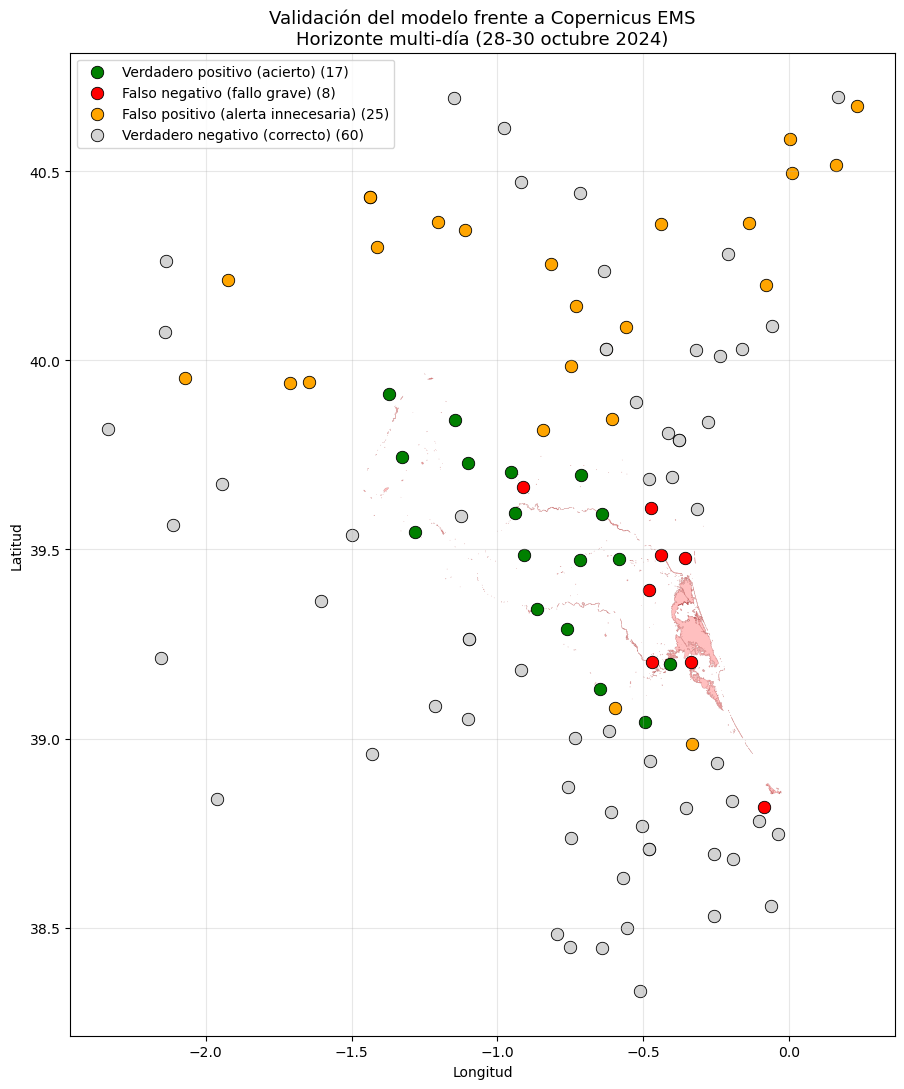

In [40]:
# Mapa actualizado con la validación multi-día
mapa_validacion_md = estaciones_gdf.merge(validacion_multidia, on='descripcion', how='inner').copy()

def clasificar_md(row):
    if row['zona_inundada'] and row['alerta_emitida']:
        return 'Verdadero positivo (acierto)'
    elif row['zona_inundada'] and not row['alerta_emitida']:
        return 'Falso negativo (fallo grave)'
    elif not row['zona_inundada'] and row['alerta_emitida']:
        return 'Falso positivo (alerta innecesaria)'
    else:
        return 'Verdadero negativo (correcto)'

mapa_validacion_md['resultado'] = mapa_validacion_md.apply(clasificar_md, axis=1)

colores = {
    'Verdadero positivo (acierto)':       'green',
    'Falso negativo (fallo grave)':       'red',
    'Falso positivo (alerta innecesaria)':'orange',
    'Verdadero negativo (correcto)':      'lightgray'
}

fig, ax = plt.subplots(figsize=(14, 11))
huella_wgs84.plot(ax=ax, color='red', alpha=0.25, edgecolor='darkred', linewidth=0.3)

for categoria, color in colores.items():
    subset = mapa_validacion_md[mapa_validacion_md['resultado'] == categoria]
    if len(subset) > 0:
        subset.plot(
            ax=ax, color=color, markersize=80, edgecolor='black', linewidth=0.6,
            label=f'{categoria} ({len(subset)})'
        )

ax.set_title('Validación del modelo frente a Copernicus EMS\nHorizonte multi-día (28-30 octubre 2024)',
             fontsize=13)
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.legend(loc='upper left', fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(Path.cwd().parent / 'data' / 'processed' / 'mapa_validacion_copernicus_multidia.png',
            dpi=150, bbox_inches='tight')
plt.show()

Lectura de las métricasRecall = 0,68 → De cada 10 estaciones que efectivamente se inundaron, el sistema alertó a 7 de ellas. En un sistema de alerta esto es la métrica más importante: prefieres alertar de más que dejar a alguien sin aviso. Un 68% es un resultado sólido.Precision = 0,40 → De cada 10 alertas que emite el sistema, 4 son correctas y 6 son "alertas en zona que no se llegó a inundar pero sí estaba en riesgo". Esto suena peor de lo que es: muchos de esos "falsos positivos" son estaciones de cabecera que recibieron lluvia extrema (Buseo, Benagéber, Domeño con 200-400 mm) pero que están aguas arriba de la zona inundada, no en ella. El sistema no está "fallando", está alertando que la cuenca está descargando, lo cual es exactamente lo que debería hacer un sistema de alerta temprana. Esto se puede argumentar muy bien en la memoria.AUC-ROC = 0,734 → Es la métrica que mejor refleja la capacidad discriminativa del modelo y que no depende del umbral. Un 0,73 es muy decente para validación frente a verdad terreno satelital independiente. Por contexto: la literatura académica suele reportar AUC entre 0,7 y 0,85 para modelos similares.F1-score = 0,507 → Balance entre precision y recall. Coherente con los anteriores.Accuracy = 0,70 → El sistema acierta en el 70% de las estaciones globalmente.

In [41]:
# Guardar la tabla completa para uso futuro
validacion_completa = mapa_validacion_md[
    ['descripcion', 'subcuenca', 'provincia', 'lat', 'lon',
     'prob_maxima', 'alerta_emitida', 'zona_inundada', 'resultado']
].copy()

output_path = PROCESSED_DIR / "validacion_copernicus.csv"
validacion_completa.to_csv(output_path, index=False, encoding='utf-8')

print(f"Guardado en: {output_path}")
print(f"\nResumen por categoría:")
print(validacion_completa['resultado'].value_counts())

Guardado en: C:\Users\Maria\Documents\tfm-flood-warning\data\processed\validacion_copernicus.csv

Resumen por categoría:
resultado
Verdadero negativo (correcto)          60
Falso positivo (alerta innecesaria)    25
Verdadero positivo (acierto)           17
Falso negativo (fallo grave)            8
Name: count, dtype: int64
